---
title: "Wycena opcji barierowej Down-and-Out Put za pomocą PyMPDATA"
author: "Kamil Kasperek"
lang: pl
format:
  pdf:
    geometry: margin=0.55in
    fontsize: 9.5pt
    echo: false
    warning: false
---

### Cel pracy i pytanie badawcze
Celem eksperymentu jest numeryczna wycena europejskiej opcji sprzedaży z dolną barierą wyłączającą (**Down-and-Out Put**) poprzez sprowadzenie modelu Blacka-Scholesa do równania adwekcji-dyfuzji i rozwiązanie go za pomocą biblioteki `PyMPDATA`. 

**Pytanie badawcze:** *Jak dobrze schemat 2. rzędu `MPDATA` radzi sobie ze stromym spadkiem wartości przy barierze $B$ oraz wyznaczeniem współczynnika Delta ($\Delta = \partial V / \partial S$) na różnych rozdzielczościach siatki w porównaniu ze zwykłym schematem `upwind`?*

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PyMPDATA-examples')

In [2]:
import numpy as np
from matplotlib import pyplot
from open_atmos_jupyter_utils import show_plot, show_anim
from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions
from scipy.special import erf

## 1. Czym jest opcja Down-and-Out Put?
Opcja *Down-and-Out Put* to opcja sprzedaży z dolną barierą wyłączającą. Daje prawo do sprzedaży akcji po ustalonej cenie wykonania (np. $K = 120\$$), pod warunkiem że kurs akcji w trakcie trwania umowy nie spadnie do poziomu bariery ($B = 80\$$) lub poniżej niej. Jeśli kurs dotknie bariery, opcja natychmiast wygasa jako bezwartościowa.

## 2. Numeryka i rozwiązanie analityczne
Równanie Blacka-Scholesa po przejściu na zmienną logarytmiczną $x = \ln(S/K)$ oraz czas wsteczny $\tau = T - t$ przyjmuje postać jednowymiarowego równania adwekcji-dyfuzji, gdzie dyfuzja odpowiada zmienności $\sigma$, a adwekcja dryfowi rynkowemu. Barierę wyłączającą $B$ modelujemy jako pochłaniający warunek brzegowy Dirichleta ($\psi = 0$ dla $S \le B$), a człon dyfuzyjny realizujemy w `PyMPDATA` przez pseudo-prędkość dyfuzyjną z zachowaniem warunku stabilności Couranta ($|C| \le 1$).

Jako punkt odniesienia wykorzystano ścisły [wzór analityczny](https://people.maths.ox.ac.uk/howison/barriers.pdf).

In [3]:
class DownAndOutPutIntegrator:
    def __init__(self, *, strike_price, barrier_price, volatility, risk_free_interest_rate, nx, options=None):
        options = options or Options(nonoscillatory=True, infinite_gauge=True, non_zero_mu_coeff=True)
        
        assert options.non_zero_mu_coeff, "Options must have non_zero_mu_coeff=True"
        assert strike_price > 0
        assert barrier_price > 0
        assert risk_free_interest_rate >= 0
        assert volatility >= 0
        assert nx > 0
        
        self.K = strike_price
        self.B = barrier_price
        self.r = risk_free_interest_rate
        self.sigma = volatility

        x_min = np.log(self.B / self.K)
        x_max = max(4.0 * np.log(self.K / self.B), 1.5)
        self.dx = (x_max - x_min) / nx
        self.x = x_min + (np.arange(nx) + 0.5) * self.dx
        self.S = self.K * np.exp(self.x)

        payout = np.where((self.B < self.S) & (self.S < self.K), self.K - self.S, 0.0)
        common = {
            'halo': options.n_halo,
            'boundary_conditions': (boundary_conditions.Constant(value=0),)
        }

        self.advectee = ScalarField(**common, data=payout)
        self.advector = VectorField(**common, data=(np.zeros(nx + 1),))
        self.solver = Solver(advector=self.advector, advectee=self.advectee, stepper=Stepper(n_dims=1, options=options))

    def __call__(self, *, nt, T, outfreq):
        dt = T / nt
        c_adv = (0.5 * self.sigma**2 - self.r) * dt / self.dx
        mu = 0.5 * self.sigma**2 * dt / (self.dx**2)

        assert abs(c_adv) + 2 * mu <= 1.0

        self.advector.get_component(0)[:] = c_adv
        output = [self.advectee.get().copy()]

        for step in range(1, nt // outfreq + 1):
            self.solver.advance(n_steps=outfreq, mu_coeff=(mu,))
            output.append(self.advectee.get().copy() * np.exp(-self.r * step * outfreq * dt))

        return output

In [4]:
def AnalyticalDownAndOutPutSolver(S, K, B, T, r, sigma):
    def N(z):
        return 0.5 * (1.0 + erf(z / np.sqrt(2.0)))

    def vanilla_put(s, strike):
        d1 = (np.log(s / strike) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)
        return strike * np.exp(-r * T) * N(-d2) - s * N(-d1)

    def binary_put(s, strike):
        d2 = (np.log(s / strike) + (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        return np.exp(-r * T) * N(-d2)

    def truncated_put(s):
        return vanilla_put(s, K) - vanilla_put(s, B) - (K - B) * binary_put(s, B)

    power = 2.0 * r / (sigma**2) - 1.0
    result = truncated_put(S) - (B / S)**power * truncated_put((B**2) / S)
    return np.where(S > B, result, 0.0)

In [5]:
def pad_barrier(S_arr, V_arr, barrier, s_min=60.0):
    return np.concatenate(([s_min, barrier], S_arr)), np.concatenate(([0.0, 0.0], V_arr))

In [6]:
def plot_results(integ_MPDATA, output_MPDATA, output_upwind, S_fine, analytical_price, analytical_delta, nx, nt):
    S = integ_MPDATA.S
    barrier = integ_MPDATA.B
    S_plot, payoff_plot = pad_barrier(S, output_MPDATA[0], barrier)
    _, mpdata_mid = pad_barrier(S, output_MPDATA[len(output_MPDATA) // 2], barrier)
    _, upwind_mid = pad_barrier(S, output_upwind[len(output_upwind) // 2], barrier)
    _, upwind_end = pad_barrier(S, output_upwind[-1], barrier)
    _, mpdata_end = pad_barrier(S, output_MPDATA[-1], barrier)
    S_fine_plot, exact_plot = pad_barrier(S_fine, analytical_price, barrier)

    mpdata_delta = np.gradient(output_MPDATA[-1], S)
    upwind_delta = np.gradient(output_upwind[-1], S)

    fig, (ax_price, ax_delta) = pyplot.subplots(1, 2, figsize=(11, 3.5))

    ax_price.plot(S_plot, payoff_plot, linestyle=':', color='gray', label='Payoff (t = T)')
    ax_price.plot(S_plot, mpdata_mid, linestyle='-.', color='tab:cyan', label='MPDATA (t = 0.5 T)')
    ax_price.plot(S_plot, upwind_mid, linestyle='-.', color='tab:orange', label='upwind (t = 0.5 T)')
    ax_price.plot(S_plot, upwind_end, linestyle='--', color='tab:red', label='upwind (t = 0)')
    ax_price.plot(S_plot, mpdata_end, color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
    ax_price.plot(S_fine_plot, exact_plot, linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')

    ax_delta.plot(S, upwind_delta, linestyle='--', color='tab:orange', label='upwind (t = 0)')
    ax_delta.plot(S, mpdata_delta, color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
    ax_delta.plot(S_fine, analytical_delta, linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')
    ax_delta.axhline(0, color='gray', linewidth=0.8)

    for ax, ylabel, title in [
        (ax_price, 'Option value V(S, t) [$]', f'Option value evolution (nx={nx}, nt={nt})'),
        (ax_delta, 'Delta Δ = ∂V / ∂S [-]', f'Portfolio sensitivity: Delta (nx={nx}, nt={nt})')
    ]:
        ax.axvline(barrier_price, color='green', linestyle='--', linewidth=1, label=f'Barrier B = {barrier}$')
        ax.set_xlim(75, 160)
        ax.set_xlabel('Asset price S [$]')
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.grid(True, alpha=0.3)

    ax_price.legend(fontsize=7.5, ncol=2)
    ax_delta.legend(fontsize=7.5)
    pyplot.tight_layout()
    pyplot.show()

## 3. Wyniki symulacji dla różnych rozdzielczości siatki

Przetestowano półroczną opcję ($T = 0{,}5\text{ roku}$) o cenie wykonania $K = 120\$$, barierze $B = 80\$$, zmienności $\sigma = 35\%$ i stopie wolnej od ryzyka $r = 5\%$ dla trzech coraz gęstszych siatek przestrzennych $n_x \in \{25, 75, 125\}$ oraz siatek czasowych $n_t \in \{250, 750, 1000\}$.

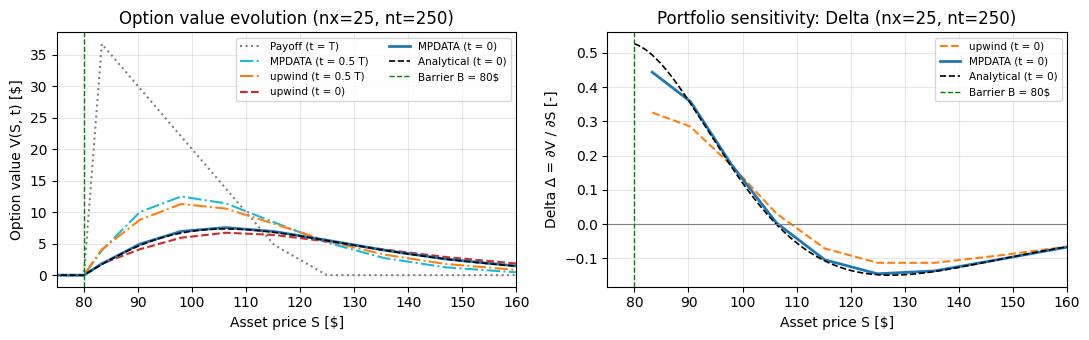

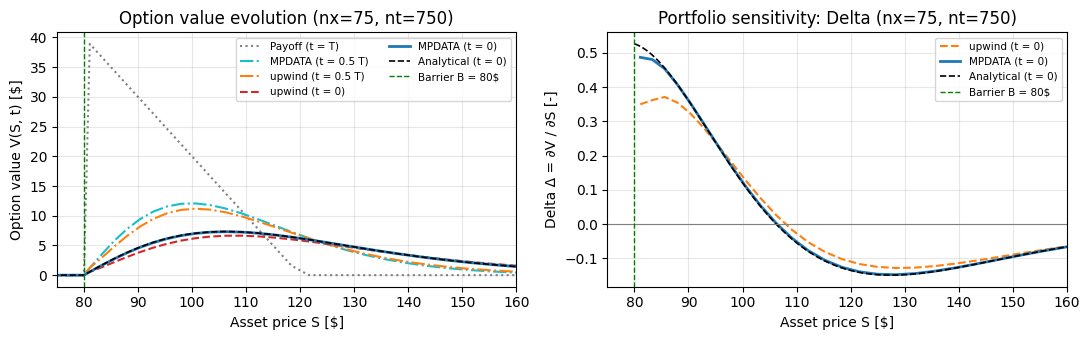

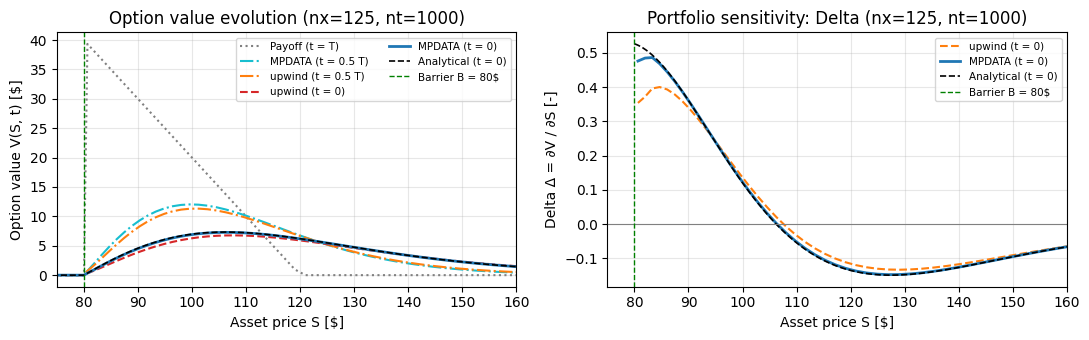

In [7]:
strike_price = 120
barrier_price = 80
volatility = 0.35
risk_free_interest_rate = 0.05
T = 0.5
nx = [25, 75, 125]
nt = [250, 750, 1000]
outfreq = [25, 75, 10]

S_fine = np.linspace(barrier_price, 200.0, 1000)
analytical_price = AnalyticalDownAndOutPutSolver(S_fine, strike_price, barrier_price, T, risk_free_interest_rate, volatility)
analytical_delta = np.gradient(analytical_price, S_fine)

errors_mpdata = []
errors_upwind = []

for i in range(3):
    integ_MPDATA = DownAndOutPutIntegrator(
        strike_price=strike_price, barrier_price=barrier_price,
        volatility=volatility, risk_free_interest_rate=risk_free_interest_rate,
        nx=nx[i]
    )
    integ_upwind = DownAndOutPutIntegrator(
        strike_price=strike_price, barrier_price=barrier_price,
        volatility=volatility, risk_free_interest_rate=risk_free_interest_rate,
        nx=nx[i], options=Options(n_iters=1, non_zero_mu_coeff=True)
    )
    
    output_MPDATA = integ_MPDATA(nt=nt[i], T=T, outfreq=outfreq[i])
    output_upwind = integ_upwind(nt=nt[i], T=T, outfreq=outfreq[i])
    
    exact = np.interp(integ_MPDATA.S, S_fine, analytical_price, right=0.0)
    errors_mpdata.append(np.sqrt(np.mean((output_MPDATA[-1] - exact)**2)))
    errors_upwind.append(np.sqrt(np.mean((output_upwind[-1] - exact)**2)))
    
    plot_results(integ_MPDATA, output_MPDATA, output_upwind, S_fine, analytical_price, analytical_delta, nx[i], nt[i])

In [8]:
assert errors_mpdata[-1] < errors_upwind[-1], "MPDATA should have a smaller error than upwind"
assert errors_mpdata[-1] < errors_mpdata[0], "Error should get smaller with increase of nx"
assert errors_mpdata[-1] < 0.25, f"Error too large L2 for nx=125: {errors_mpdata[-1]:.4f}"
assert np.all(output_MPDATA[-1] >= 0.0), "Price of asset cannot be negative"

In [9]:
from matplotlib.animation import FuncAnimation, PillowWriter

dt_frame = T / (len(output_MPDATA) - 1)
y_max = np.max(output_MPDATA[0]) * 1.1
S_plot, _ = pad_barrier(integ_MPDATA.S, output_MPDATA[0], barrier_price)
S_fine_plot, exact_plot = pad_barrier(S_fine, analytical_price, barrier_price)

fig, ax = pyplot.subplots(figsize=(7, 4))

def update(frame):
    ax.clear()
    t_remaining = T - frame * dt_frame
    _, mpdata_frame = pad_barrier(integ_MPDATA.S, output_MPDATA[frame], barrier_price)
    _, upwind_frame = pad_barrier(integ_MPDATA.S, output_upwind[frame], barrier_price)

    ax.fill_between(S_plot, mpdata_frame, color='tab:blue', alpha=0.25)
    ax.plot(S_plot, mpdata_frame, color='tab:blue', linewidth=2, label='MPDATA')
    ax.plot(S_plot, upwind_frame, color='tab:orange', linestyle='--', linewidth=1.5, label='upwind')
    ax.plot(S_fine_plot, exact_plot, color='black', linestyle=':', linewidth=1.2, label='Analytical (t = 0)')
    ax.axvline(barrier_price, color='green', linestyle='--', linewidth=1.5, label=f'Barrier B = {barrier_price}$')
    ax.set_xlim(65, 200)
    ax.set_ylim(-1, y_max)
    ax.set_xlabel('Asset price S [$]')
    ax.set_ylabel('Option value V(S, t) [$]')
    ax.set_title(f'Option value evolution (nx=125, nt=1000) – {t_remaining:.3f} years remaining')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')

anim = FuncAnimation(fig, update, frames=len(output_MPDATA), interval=80)
anim.save('animation.gif', writer=PillowWriter(fps=15))
pyplot.close(fig)

### Wnioski
- **Zbieżność na siatce:** Już przy rzadkiej siatce widać, jak dyfuzja numeryczna schematu `upwind` zaniża wycenę opcji i spłaszcza krzywą $\Delta$. Wraz ze zagęszczaniem siatki `MPDATA` niemal idealnie pokrywa się z rozwiązaniem analitycznym, podczas gdy `upwind` wyraźnie od niego odstaje.
- **Zachowanie Delty przy samej barierze:** Tuż przy barierze ($S \to B^+$) widać dla obu schematów lokalne odchylenie od krzywej analitycznej (wynikające z ostrego warunku brzegowego $\psi = 0$ i numerycznego różniczkowania na krawędzi siatki). Schemat `upwind` wyraźnie traci tu dokładność, natomiast `MPDATA` bardzo dobrze odtwarza przebieg $\Delta$, wykazując jedynie niewielkie zniekształcenie brzegowe w pierwszej komórce przy barierze, a co ciekawe, zniekształcenie to powiększa się wraz z dokładnością siatki.
- **Dodatek:** Pełny przebieg czasowy ewolucji wartości opcji dla najgęstszej siatki ($n_x = 125, n_t = 1000$) został zapisany jako osobny artefakt `animation.gif`.